In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the training dataset
df = pd.read_csv("train.csv")

# Display the first five rows
df.head()


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [2]:

import os
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

# Create a folder for all project visualizations
GRAPH_DIR = "graphs and visuals"
os.makedirs(GRAPH_DIR, exist_ok=True)

print("Graphs folder:", os.path.abspath(GRAPH_DIR))


Graphs folder: c:\Users\joshi\Documents\Data Science Projects\House Price Analysis & Prediction\graphs and visuals


In [3]:

print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()


Dataset shape: (1460, 81)

Column names:
['Id', 'MSSubClass', 'MSZoning', 'LotFrontage', 'LotArea', 'Street', 'Alley', 'LotShape', 'LandContour', 'Utilities', 'LotConfig', 'LandSlope', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType', 'HouseStyle', 'OverallQual', 'OverallCond', 'YearBuilt', 'YearRemodAdd', 'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType', 'MasVnrArea', 'ExterQual', 'ExterCond', 'Foundation', 'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinSF1', 'BsmtFinType2', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', 'Heating', 'HeatingQC', 'CentralAir', 'Electrical', '1stFlrSF', '2ndFlrSF', 'LowQualFinSF', 'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath', 'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'KitchenQual', 'TotRmsAbvGrd', 'Functional', 'Fireplaces', 'FireplaceQu', 'GarageType', 'GarageYrBlt', 'GarageFinish', 'GarageCars', 'GarageArea', 'GarageQual', 'GarageCond', 'PavedDrive', 'WoodDeckSF', 'OpenPorchSF', 'EnclosedPorch', '3SsnPo

In [4]:

df.describe().T


,count,mean,std,min,25%,50%,75%,max
Id,1460.0,730.500000,421.610009,1.0,365.75,730.5,1095.25,1460.0
MSSubClass,1460.0,56.897260,42.300571,20.0,20.00,50.0,70.00,190.0
LotFrontage,1201.0,70.049958,24.284752,21.0,59.00,69.0,80.00,313.0
LotArea,1460.0,10516.828082,9981.264932,1300.0,7553.50,9478.5,11601.50,215245.0
OverallQual,1460.0,6.099315,1.382997,1.0,5.00,6.0,7.00,10.0
OverallCond,1460.0,5.575342,1.112799,1.0,5.00,5.0,6.00,9.0
YearBuilt,1460.0,1971.267808,30.202904,1872.0,1954.00,1973.0,2000.00,2010.0
YearRemodAdd,1460.0,1984.865753,20.645407,1950.0,1967.00,1994.0,2004.00,2010.0
MasVnrArea,1452.0,103.685262,181.066207,0.0,0.00,0.0,166.00,1600.0
BsmtFinSF1,1460.0,443.639726,456.098091,0.0,0.00,383.5,712.25,5644.0


In [5]:

# Count missing values in each column
missing_values = df.isnull().sum()

# Keep only columns with missing values
missing_values = missing_values[missing_values > 0].sort_values(ascending=False)

# Display missing-value counts and percentages
missing_summary = pd.DataFrame({
    "Missing Count": missing_values,
    "Missing Percentage": (missing_values / len(df) * 100).round(2)
})

missing_summary


,Missing Count,Missing Percentage
PoolQC,1453,99.52
MiscFeature,1406,96.30
Alley,1369,93.77
Fence,1179,80.75
MasVnrType,872,59.73
FireplaceQu,690,47.26
LotFrontage,259,17.74
GarageType,81,5.55
GarageYrBlt,81,5.55
GarageFinish,81,5.55


In [6]:

print("Duplicate rows:", df.duplicated().sum())
print("Duplicate IDs:", df["Id"].duplicated().sum())

print("\nSalePrice summary:")
print(df["SalePrice"].describe())

print("\nMissing SalePrice values:", df["SalePrice"].isnull().sum())


Duplicate rows: 0
Duplicate IDs: 0

SalePrice summary:
count      1460.000000
mean     180921.195890
std       79442.502883
min       34900.000000
25%      129975.000000
50%      163000.000000
75%      214000.000000
max      755000.000000
Name: SalePrice, dtype: float64

Missing SalePrice values: 0


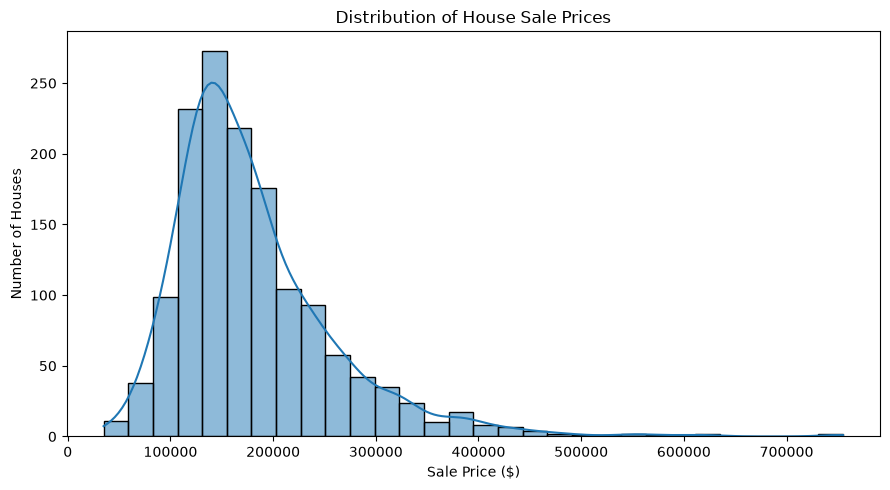

In [7]:
plt.figure(figsize=(9, 5))

sns.histplot(df["SalePrice"], kde=True, bins=30)

plt.title("Distribution of House Sale Prices")
plt.xlabel("Sale Price ($)")
plt.ylabel("Number of Houses")
plt.tight_layout()

plt.savefig(
    os.path.join(GRAPH_DIR, "01_sale_price_distribution.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()



## Data Cleaning and Missing Value Treatment

The dataset contains missing values in several numerical and categorical features. The missing-value pattern varies across columns, so a single treatment method is not appropriate for every feature.

Some categorical missing values indicate the absence of a property feature, such as a pool or alley access. Other missing values represent information that was not recorded.

The cleaning process will distinguish between these cases, use appropriate imputation strategies, and preserve the original dataset for comparison.


In [8]:
# Keep the original dataset unchanged
df_clean = df.copy()

# Check missing values before cleaning
print("Missing values before cleaning:",
      df_clean.isnull().sum().sum())


Missing values before cleaning: 7829


In [9]:
# Categorical features where missing indicates the feature is absent
absent_feature_cols = [
    "PoolQC",
    "MiscFeature",
    "Alley",
    "Fence",
    "MasVnrType",
    "FireplaceQu",
    "GarageType",
    "GarageFinish",
    "GarageQual",
    "GarageCond",
    "BsmtExposure",
    "BsmtFinType2",
    "BsmtQual",
    "BsmtCond",
    "BsmtFinType1"
]

# Apply only to columns that exist in the dataset
absent_feature_cols = [
    col for col in absent_feature_cols if col in df_clean.columns
]

for col in absent_feature_cols:
    df_clean[col] = df_clean[col].fillna("None")

print("Missing values remaining in these columns:")
print(df_clean[absent_feature_cols].isnull().sum())


Missing values remaining in these columns:
PoolQC          0
MiscFeature     0
Alley           0
Fence           0
MasVnrType      0
FireplaceQu     0
GarageType      0
GarageFinish    0
GarageQual      0
GarageCond      0
BsmtExposure    0
BsmtFinType2    0
BsmtQual        0
BsmtCond        0
BsmtFinType1    0
dtype: int64


In [10]:
# Separate numerical and categorical columns
numeric_cols = df_clean.select_dtypes(include="number").columns
categorical_cols = df_clean.select_dtypes(
    include=["object", "category", "str"]
).columns

# Fill remaining numerical missing values with the median
for col in numeric_cols:
    if df_clean[col].isnull().any():
        df_clean[col] = df_clean[col].fillna(df_clean[col].median())

# Fill remaining categorical missing values with the mode
for col in categorical_cols:
    if df_clean[col].isnull().any():
        mode_values = df_clean[col].mode()
        if not mode_values.empty:
            df_clean[col] = df_clean[col].fillna(mode_values.iloc[0])

print("Total missing values after cleaning:",
      df_clean.isnull().sum().sum())


Total missing values after cleaning: 0


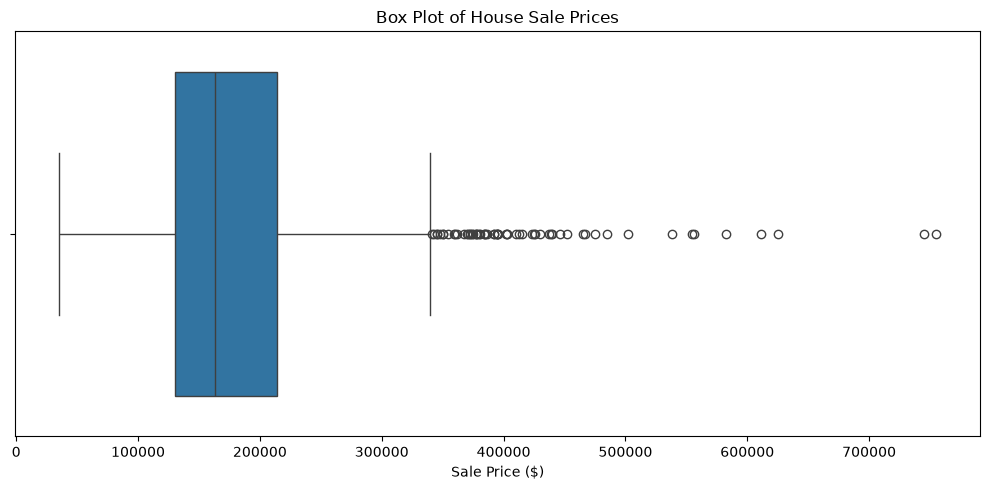

In [11]:
plt.figure(figsize=(10, 5))

sns.boxplot(x=df_clean["SalePrice"])

plt.title("Box Plot of House Sale Prices")
plt.xlabel("Sale Price ($)")
plt.tight_layout()

plt.savefig(
    os.path.join(GRAPH_DIR, "02_sale_price_boxplot.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()


In [12]:

Q1 = df_clean["SalePrice"].quantile(0.25)
Q3 = df_clean["SalePrice"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df_clean[
    (df_clean["SalePrice"] < lower_bound) |
    (df_clean["SalePrice"] > upper_bound)
]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)
print("Potential outlier count:", len(outliers))


Q1: 129975.0
Q3: 214000.0
IQR: 84025.0
Lower bound: 3937.5
Upper bound: 340037.5
Potential outlier count: 61


In [13]:

df_clean.nlargest(10, "SalePrice")[
    ["Id", "OverallQual", "GrLivArea", "GarageCars",
     "TotalBsmtSF", "YearBuilt", "SalePrice"]
]


,Id,OverallQual,GrLivArea,GarageCars,TotalBsmtSF,YearBuilt,SalePrice
691,692,10,4316,3,2444,1994,755000
1182,1183,10,4476,3,2396,1996,745000
1169,1170,10,3627,3,1930,1995,625000
898,899,9,2364,3,2330,2009,611657
803,804,9,2822,3,1734,2008,582933
1046,1047,9,2868,3,1992,2005,556581
440,441,10,2402,3,3094,2008,555000
769,770,8,3279,3,1650,2003,538000
178,179,9,2234,3,2216,2008,501837
798,799,9,3140,3,1926,2008,485000



## Exploratory Data Analysis (EDA)

Exploratory data analysis is performed to understand the distribution of house prices and investigate relationships between property characteristics and sale prices.

The sale price distribution is right-skewed, with most houses concentrated in the lower-to-middle price range and a smaller number of expensive properties.

The IQR method identified 61 potential high-price outliers. However, several of these properties also have high overall quality and large living areas. Therefore, these observations will be retained for further analysis unless evidence suggests that they are erroneous.


In [14]:

# Select important numerical features
important_features = [
    "SalePrice",
    "OverallQual",
    "GrLivArea",
    "GarageCars",
    "TotalBsmtSF",
    "YearBuilt",
    "FullBath",
    "BedroomAbvGr"
]

# Calculate correlations with SalePrice
correlations = (
    df_clean[important_features]
    .corr(numeric_only=True)["SalePrice"]
    .sort_values(ascending=False)
)

print(correlations)


SalePrice       1.000000
OverallQual     0.790982
GrLivArea       0.708624
GarageCars      0.640409
TotalBsmtSF     0.613581
FullBath        0.560664
YearBuilt       0.522897
BedroomAbvGr    0.168213
Name: SalePrice, dtype: float64


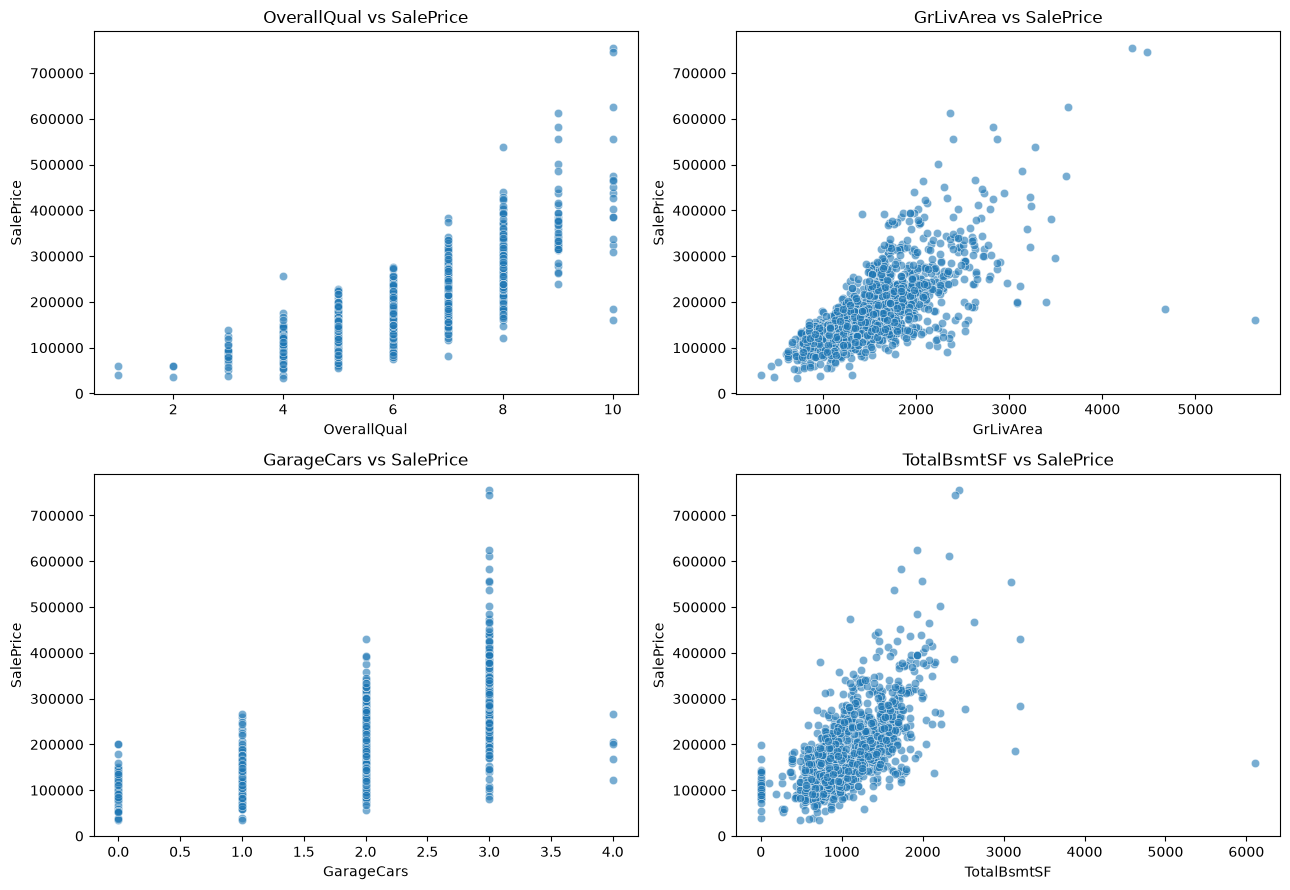

In [15]:

features_to_plot = [
    "OverallQual",
    "GrLivArea",
    "GarageCars",
    "TotalBsmtSF"
]

fig, axes = plt.subplots(2, 2, figsize=(13, 9))

for feature, ax in zip(features_to_plot, axes.flatten()):
    sns.scatterplot(
        data=df_clean,
        x=feature,
        y="SalePrice",
        alpha=0.6,
        ax=ax
    )
    ax.set_title(f"{feature} vs SalePrice")

plt.tight_layout()

fig.savefig(
    os.path.join(GRAPH_DIR, "08_feature_relationships_overview.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()


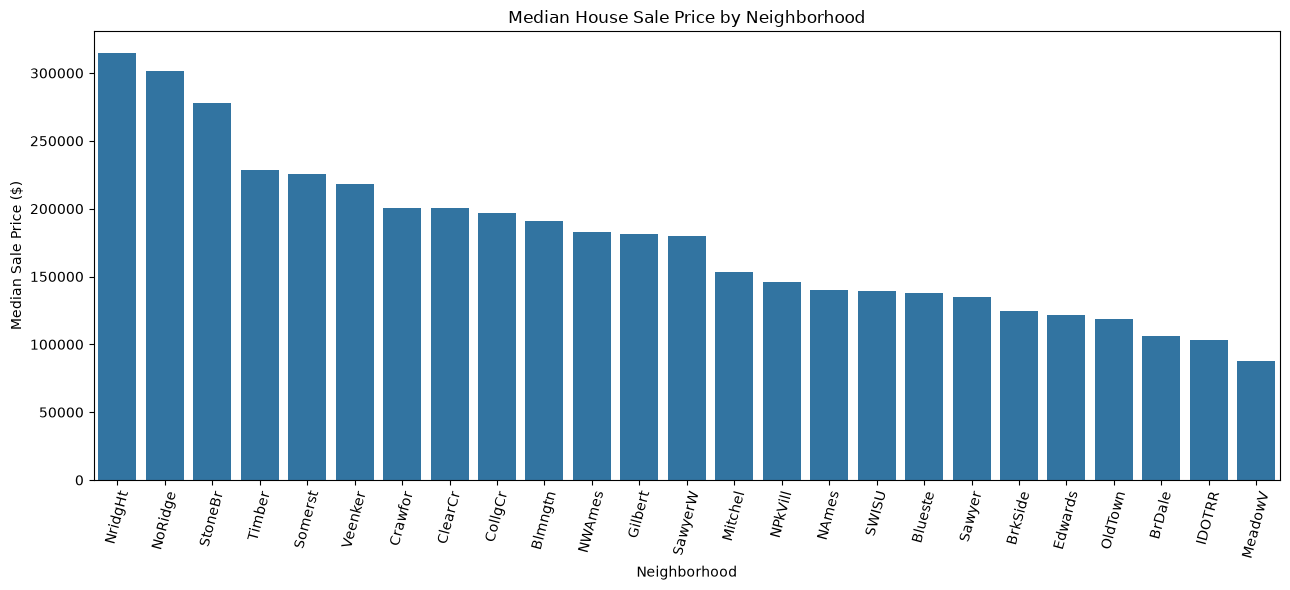

In [16]:
neighborhood_prices = (
    df_clean.groupby("Neighborhood")["SalePrice"]
    .median()
    .sort_values(ascending=False)
)

plt.figure(figsize=(13, 6))

sns.barplot(
    x=neighborhood_prices.index,
    y=neighborhood_prices.values
)

plt.title("Median House Sale Price by Neighborhood")
plt.xlabel("Neighborhood")
plt.ylabel("Median Sale Price ($)")
plt.xticks(rotation=75)

plt.tight_layout()

plt.savefig(
    os.path.join(GRAPH_DIR, "07_neighborhood_median_sale_price.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()


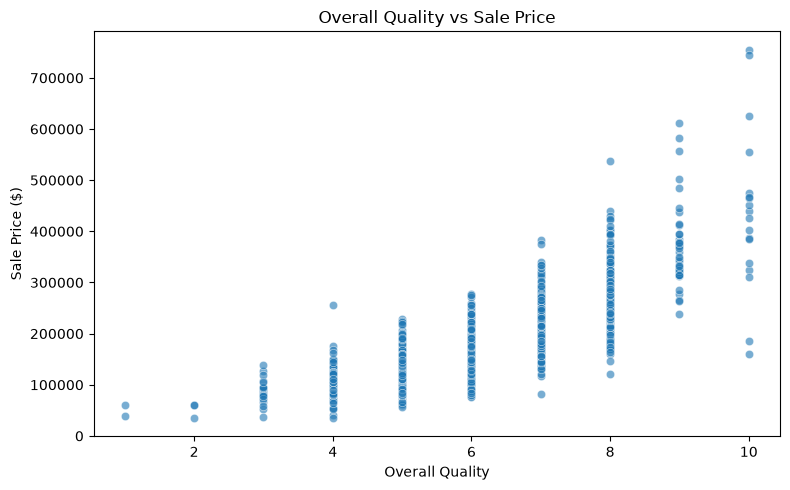

In [17]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df_clean,
    x="OverallQual",
    y="SalePrice",
    alpha=0.6
)

plt.title("Overall Quality vs Sale Price")
plt.xlabel("Overall Quality")
plt.ylabel("Sale Price ($)")
plt.tight_layout()

plt.savefig(
    os.path.join(GRAPH_DIR, "03_overall_quality_vs_sale_price.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()


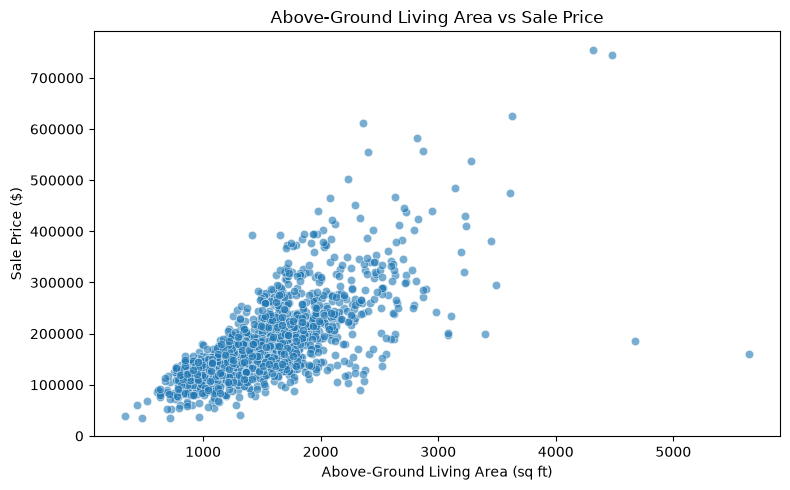

In [18]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df_clean,
    x="GrLivArea",
    y="SalePrice",
    alpha=0.6
)

plt.title("Above-Ground Living Area vs Sale Price")
plt.xlabel("Above-Ground Living Area (sq ft)")
plt.ylabel("Sale Price ($)")
plt.tight_layout()

plt.savefig(
    os.path.join(GRAPH_DIR, "04_living_area_vs_sale_price.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()


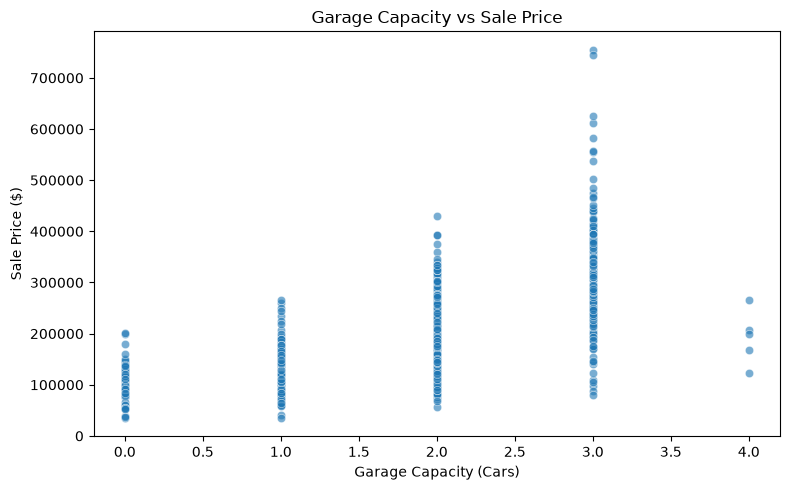

In [19]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df_clean,
    x="GarageCars",
    y="SalePrice",
    alpha=0.6
)

plt.title("Garage Capacity vs Sale Price")
plt.xlabel("Garage Capacity (Cars)")
plt.ylabel("Sale Price ($)")
plt.tight_layout()

plt.savefig(
    os.path.join(GRAPH_DIR, "05_garage_capacity_vs_sale_price.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()


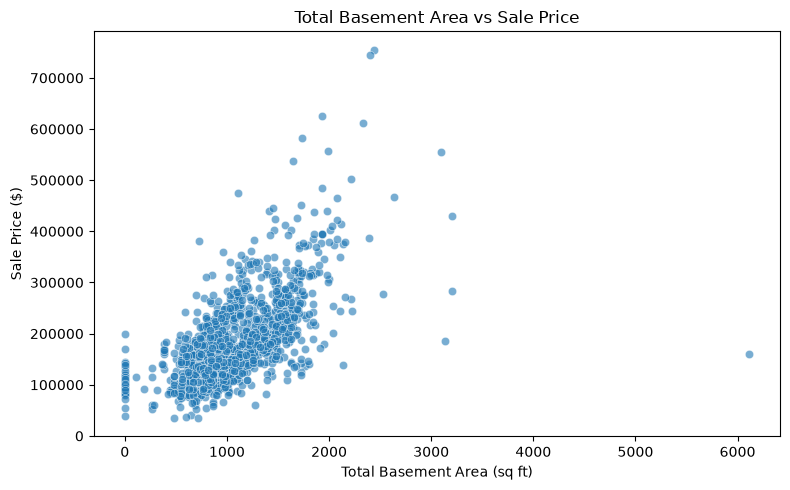

In [20]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df_clean,
    x="TotalBsmtSF",
    y="SalePrice",
    alpha=0.6
)

plt.title("Total Basement Area vs Sale Price")
plt.xlabel("Total Basement Area (sq ft)")
plt.ylabel("Sale Price ($)")
plt.tight_layout()

plt.savefig(
    os.path.join(GRAPH_DIR, "06_basement_area_vs_sale_price.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()


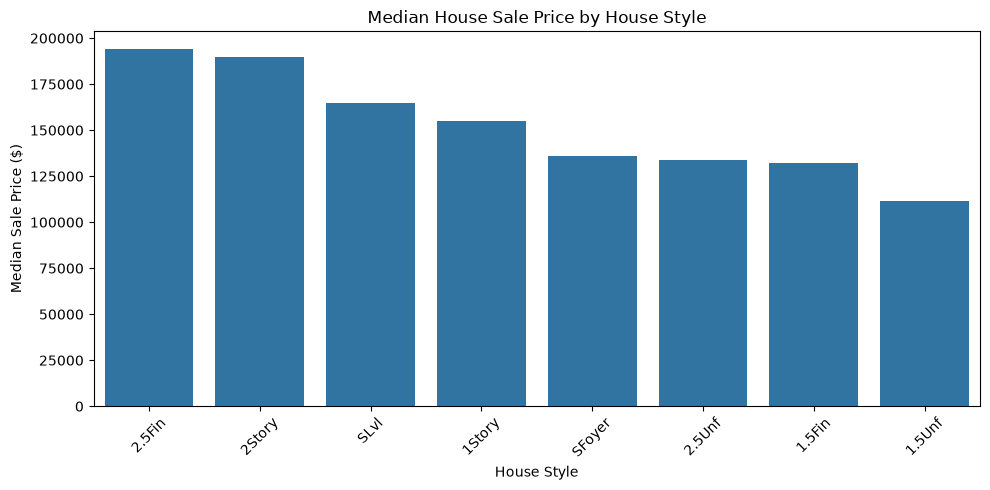

In [21]:

style_prices = (
    df_clean.groupby("HouseStyle")["SalePrice"]
    .median()
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, 5))

sns.barplot(
    x=style_prices.index,
    y=style_prices.values
)

plt.title("Median House Sale Price by House Style")
plt.xlabel("House Style")
plt.ylabel("Median Sale Price ($)")
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(
    os.path.join(GRAPH_DIR, "09_house_style_vs_sale_price.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()


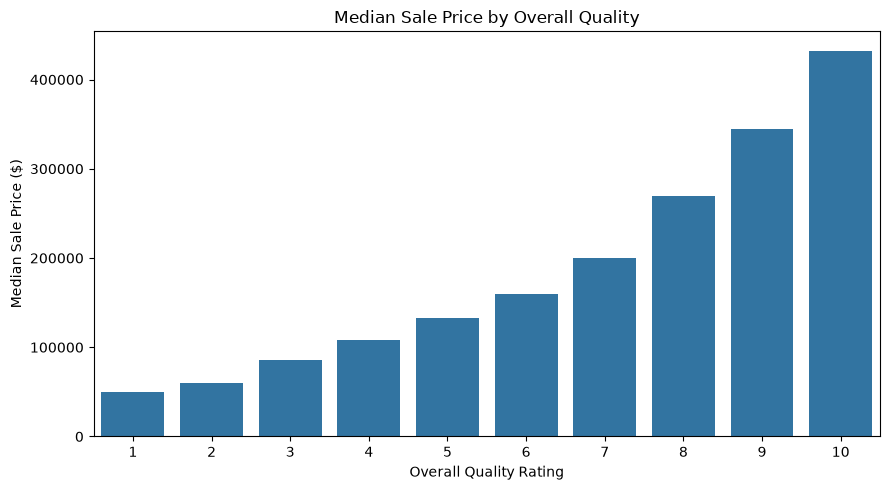

In [22]:

quality_prices = (
    df_clean.groupby("OverallQual")["SalePrice"]
    .median()
)

plt.figure(figsize=(9, 5))

sns.barplot(
    x=quality_prices.index,
    y=quality_prices.values
)

plt.title("Median Sale Price by Overall Quality")
plt.xlabel("Overall Quality Rating")
plt.ylabel("Median Sale Price ($)")
plt.tight_layout()

plt.savefig(
    os.path.join(GRAPH_DIR, "10_quality_vs_median_sale_price.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()



## Key Findings from Exploratory Data Analysis

- OverallQual has a strong positive correlation with SalePrice.
- GrLivArea is positively associated with SalePrice, although some large properties do not follow the general trend.
- GarageCars and TotalBsmtSF also show positive relationships with sale prices.
- Median sale prices differ across neighborhoods, suggesting that location contains useful predictive information.
- The sale price distribution is right-skewed, and high-priced properties require careful evaluation rather than automatic removal.

These findings will guide feature preparation and regression model development. Correlations describe associations and do not establish causation.


In [23]:

from sklearn.model_selection import train_test_split

# Remove the target and the ID column from the input features
X = df_clean.drop(columns=["SalePrice", "Id"])
y = df_clean["SalePrice"]

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)

print("\nNumerical features:", X.select_dtypes(include="number").shape[1])
print("Categorical features:", X.select_dtypes(exclude="number").shape[1])


Feature matrix shape: (1460, 79)
Target shape: (1460,)

Numerical features: 36
Categorical features: 43


In [24]:

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])


Training samples: 1168
Testing samples: 292


In [25]:

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import numpy as np
import pandas as pd


In [26]:

# Identify feature types using the training data
numeric_features = X_train.select_dtypes(include="number").columns.tolist()
categorical_features = X_train.select_dtypes(
    exclude="number"
).columns.tolist()

# Numerical preprocessing
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both preprocessing pipelines
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

print("Numerical features:", len(numeric_features))
print("Categorical features:", len(categorical_features))


Numerical features: 36
Categorical features: 43


In [27]:

models = {
    "Linear Regression": LinearRegression(),

    "Decision Tree": DecisionTreeRegressor(
        random_state=42,
        max_depth=10,
        min_samples_leaf=5
    ),

    "Random Forest": RandomForestRegressor(
        n_estimators=200,
        random_state=42,
        min_samples_leaf=2,
        n_jobs=-1
    )
}

print("Models prepared:", list(models.keys()))


Models prepared: ['Linear Regression', 'Decision Tree', 'Random Forest']


In [28]:

results = []
trained_models = {}
predictions = {}

for name, model in models.items():
    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    pipeline.fit(X_train, y_train)

    y_pred = pipeline.predict(X_test)

    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)

    results.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    })

    trained_models[name] = pipeline
    predictions[name] = y_pred

results_df = pd.DataFrame(results).sort_values("RMSE")
results_df = results_df.reset_index(drop=True)

results_df.round(3)


,Model,MAE,RMSE,R2
0,Random Forest,17586.082,28950.702,0.891
1,Linear Regression,20592.748,31171.856,0.873
2,Decision Tree,27189.892,43952.472,0.748


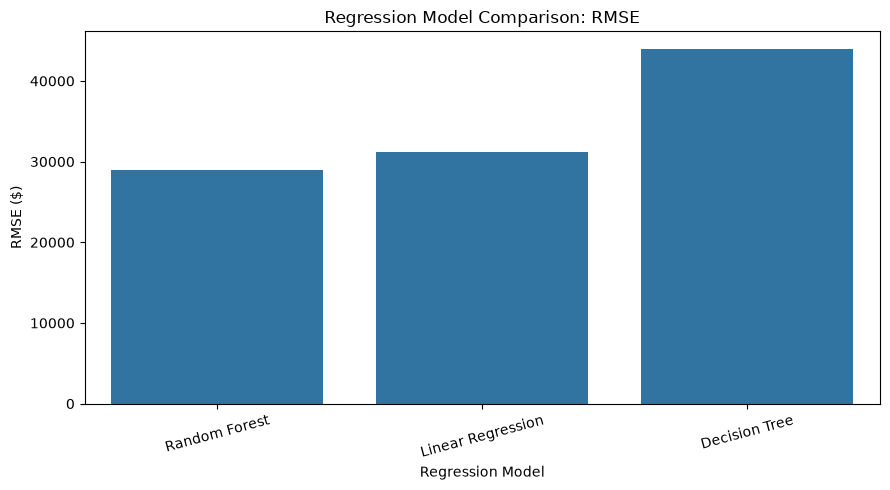

In [29]:

# Compare the three models using RMSE
plt.figure(figsize=(9, 5))

sns.barplot(
    data=results_df,
    x="Model",
    y="RMSE"
)

plt.title("Regression Model Comparison: RMSE")
plt.xlabel("Regression Model")
plt.ylabel("RMSE ($)")
plt.xticks(rotation=15)
plt.tight_layout()

plt.savefig(
    os.path.join(GRAPH_DIR, "11_regression_model_comparison_rmse.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()


In [30]:

# Retrieve the fitted preprocessing and Random Forest model
best_pipeline = trained_models["Random Forest"]

fitted_preprocessor = best_pipeline.named_steps["preprocessor"]
rf_model = best_pipeline.named_steps["model"]

# Retrieve feature names after preprocessing
feature_names = fitted_preprocessor.get_feature_names_out()

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": rf_model.feature_importances_
})

importance_df = importance_df.sort_values(
    "Importance",
    ascending=False
).reset_index(drop=True)

importance_df.head(15)


,Feature,Importance
0,num__OverallQual,0.564384
1,num__GrLivArea,0.123726
2,num__TotalBsmtSF,0.033435
3,num__2ndFlrSF,0.030050
4,num__BsmtFinSF1,0.027861
5,num__1stFlrSF,0.027575
6,num__LotArea,0.017939
7,num__GarageArea,0.015552
8,num__GarageCars,0.014511
9,num__YearBuilt,0.012714


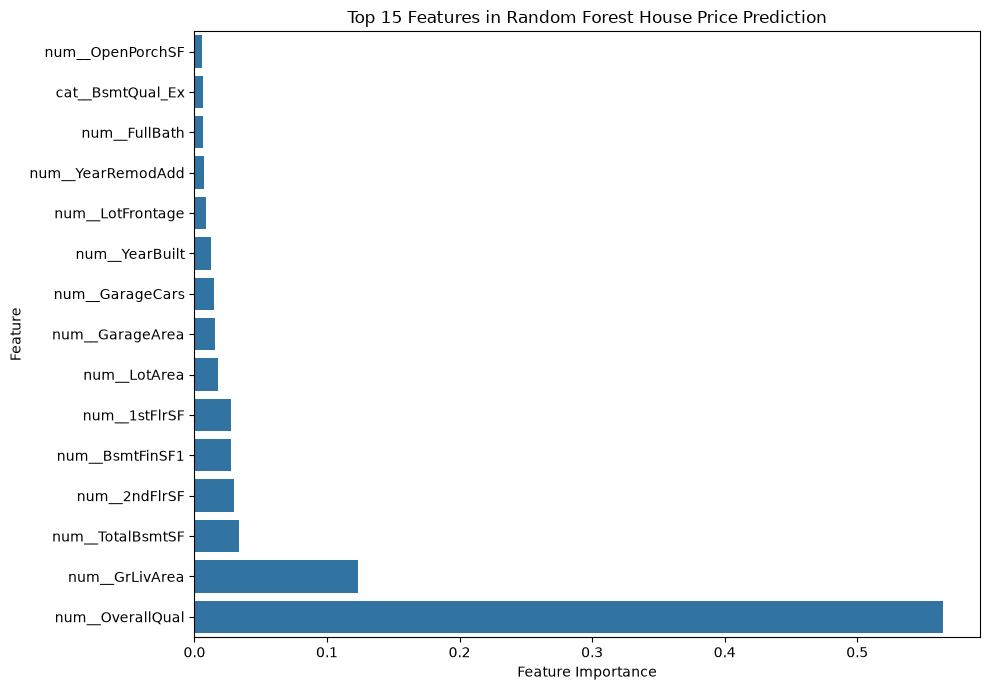

In [31]:

top_features = importance_df.head(15).sort_values("Importance")

plt.figure(figsize=(10, 7))

sns.barplot(
    data=top_features,
    x="Importance",
    y="Feature"
)

plt.title("Top 15 Features in Random Forest House Price Prediction")
plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.tight_layout()

plt.savefig(
    os.path.join(GRAPH_DIR, "12_random_forest_feature_importance.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()



## Feature Importance Analysis

The Random Forest feature importance analysis identified OverallQual as the most influential feature in the model, followed by GrLivArea and TotalBsmtSF.

OverallQual represents the overall material and finish quality of a property, while GrLivArea represents above-ground living area. These findings are consistent with the exploratory analysis, which showed a strong positive relationship between overall quality and sale price.

Other useful predictors include first-floor area, basement area, garage characteristics, and year built. The results suggest that both property quality and usable space provide important information for house price prediction.

Feature importance describes the model's reliance on individual features and does not establish causation. The importance of correlated features may also be distributed across multiple variables.


In [32]:

# Train a Random Forest on log-transformed sale prices
log_rf_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=200,
        random_state=42,
        min_samples_leaf=2,
        n_jobs=-1
    ))
])

log_rf_pipeline.fit(X_train, np.log1p(y_train))

# Convert predictions back to dollars
log_predictions = np.expm1(log_rf_pipeline.predict(X_test))

log_results = {
    "Model": "Random Forest (Log Target)",
    "MAE": mean_absolute_error(y_test, log_predictions),
    "RMSE": np.sqrt(mean_squared_error(y_test, log_predictions)),
    "R2": r2_score(y_test, log_predictions)
}

print(pd.DataFrame([log_results]).round(3).to_string(index=False))


                     Model       MAE      RMSE    R2
Random Forest (Log Target) 17204.315 29228.802 0.889


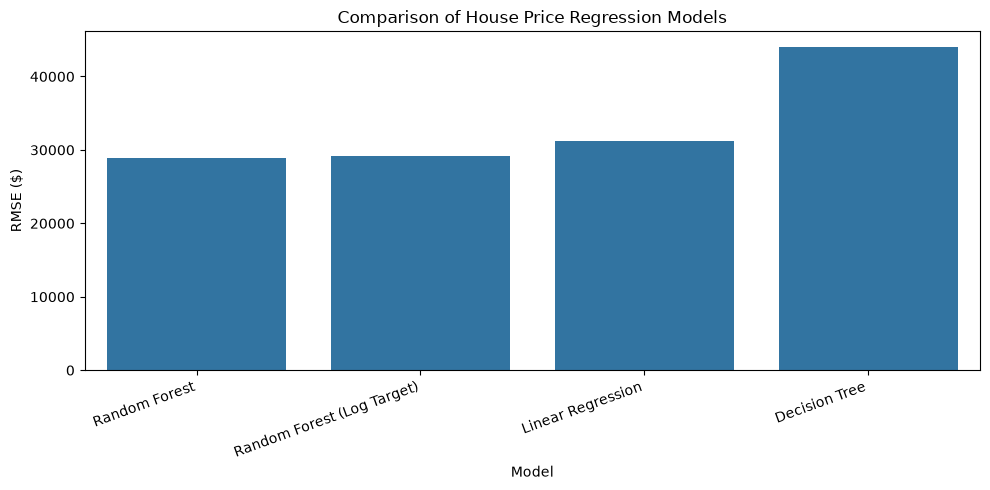

,Model,MAE,RMSE,R2
0,Random Forest,17586.082,28950.702,0.891
3,Random Forest (Log Target),17204.315,29228.802,0.889
1,Linear Regression,20592.748,31171.856,0.873
2,Decision Tree,27189.892,43952.472,0.748


In [33]:

# Combine the original three models with the log-target experiment
all_results = pd.concat(
    [
        results_df,
        pd.DataFrame([log_results])
    ],
    ignore_index=True
)

# Save and display an RMSE comparison
plt.figure(figsize=(10, 5))

sns.barplot(
    data=all_results.sort_values("RMSE"),
    x="Model",
    y="RMSE"
)

plt.title("Comparison of House Price Regression Models")
plt.xlabel("Model")
plt.ylabel("RMSE ($)")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()

plt.savefig(
    os.path.join(GRAPH_DIR, "13_final_regression_model_comparison.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()

all_results.sort_values("RMSE").round(3)


In [34]:

# Create a fresh modeling dataset from the original data
X_model = df.drop(columns=["SalePrice", "Id"]).copy()
y_model = df["SalePrice"].copy()

# Split before fitting any preprocessing
from sklearn.model_selection import train_test_split

X_train_v2, X_test_v2, y_train_v2, y_test_v2 = train_test_split(
    X_model,
    y_model,
    test_size=0.2,
    random_state=42
)

print("Training samples:", len(X_train_v2))
print("Testing samples:", len(X_test_v2))
print("Missing values in raw training features:",
      X_train_v2.isnull().sum().sum())


Training samples: 1168
Testing samples: 292
Missing values in raw training features: 6227


In [36]:

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

# Identify column types from the training features
numeric_features_v2 = X_train_v2.select_dtypes(
    include="number"
).columns.tolist()

categorical_features_v2 = X_train_v2.select_dtypes(
    exclude="number"
).columns.tolist()

# Impute numerical and categorical columns separately
numeric_pipeline_v2 = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_pipeline_v2 = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor_v2 = ColumnTransformer([
    ("num", numeric_pipeline_v2, numeric_features_v2),
    ("cat", categorical_pipeline_v2, categorical_features_v2)
])

# Put preprocessing and the model into one pipeline
rf_pipeline_v2 = Pipeline([
    ("preprocessor", preprocessor_v2),
    ("model", RandomForestRegressor(
        n_estimators=200,
        random_state=42,
        min_samples_leaf=2,
        n_jobs=-1
    ))
])

# Train only on the training split
rf_pipeline_v2.fit(X_train_v2, y_train_v2)

# Evaluate on the untouched test split
pred_v2 = rf_pipeline_v2.predict(X_test_v2)

print("MAE:", round(mean_absolute_error(y_test_v2, pred_v2), 2))
print("RMSE:", round(np.sqrt(mean_squared_error(y_test_v2, pred_v2)), 2))
print("R²:", round(r2_score(y_test_v2, pred_v2), 4))


MAE: 17525.45
RMSE: 28835.69
R²: 0.8916


In [37]:

from sklearn.model_selection import KFold, cross_validate

cv = KFold(n_splits=5, shuffle=True, random_state=42)

cv_results = cross_validate(
    rf_pipeline_v2,
    X_train_v2,
    y_train_v2,
    cv=cv,
    scoring={
        "mae": "neg_mean_absolute_error",
        "rmse": "neg_root_mean_squared_error",
        "r2": "r2"
    },
    n_jobs=1,
    return_train_score=False
)

cv_summary = pd.DataFrame({
    "Fold": range(1, 6),
    "MAE": -cv_results["test_mae"],
    "RMSE": -cv_results["test_rmse"],
    "R2": cv_results["test_r2"]
})

display(cv_summary.round(3))

print("\nAverage cross-validation performance:")
print(cv_summary[["MAE", "RMSE", "R2"]].mean().round(3))

print("\nStandard deviation across folds:")
print(cv_summary[["MAE", "RMSE", "R2"]].std().round(3))


,Fold,MAE,RMSE,R2
0,1,17245.681,26604.528,0.890
1,2,18915.517,34311.627,0.799
2,3,20130.686,38746.943,0.777
3,4,17771.887,26668.109,0.870
4,5,17436.903,26756.560,0.864



Average cross-validation performance:
MAE     18300.135
RMSE    30617.553
R2          0.840
dtype: float64

Standard deviation across folds:
MAE     1210.961
RMSE    5620.118
R2         0.049
dtype: float64


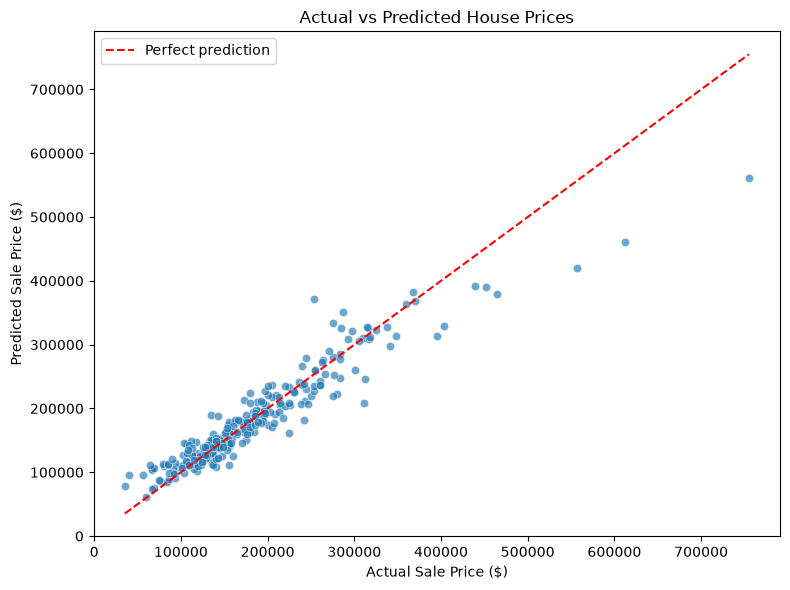

In [38]:

# Actual vs predicted house prices
plt.figure(figsize=(8, 6))

sns.scatterplot(
    x=y_test_v2,
    y=pred_v2,
    alpha=0.65
)

# Reference line for perfect predictions
min_price = min(y_test_v2.min(), pred_v2.min())
max_price = max(y_test_v2.max(), pred_v2.max())

plt.plot(
    [min_price, max_price],
    [min_price, max_price],
    linestyle="--",
    color="red",
    label="Perfect prediction"
)

plt.title("Actual vs Predicted House Prices")
plt.xlabel("Actual Sale Price ($)")
plt.ylabel("Predicted Sale Price ($)")
plt.legend()
plt.tight_layout()

plt.savefig(
    os.path.join(GRAPH_DIR, "14_actual_vs_predicted_prices.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()


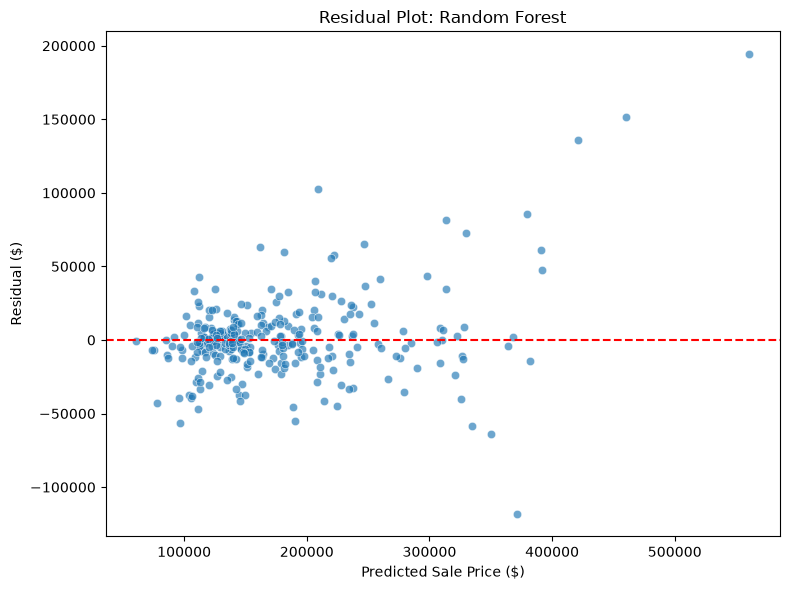

In [39]:

# Residual = actual price - predicted price
residuals = y_test_v2.to_numpy() - pred_v2

plt.figure(figsize=(8, 6))

sns.scatterplot(
    x=pred_v2,
    y=residuals,
    alpha=0.65
)

plt.axhline(0, color="red", linestyle="--")

plt.title("Residual Plot: Random Forest")
plt.xlabel("Predicted Sale Price ($)")
plt.ylabel("Residual ($)")
plt.tight_layout()

plt.savefig(
    os.path.join(GRAPH_DIR, "15_random_forest_residuals.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()



## Prediction Diagnostics

The actual-versus-predicted plot shows that the Random Forest model predicts many houses in the lower-to-middle price range reasonably well. However, some high-priced properties are substantially underpredicted.

The residual plot shows that prediction errors become more spread out as predicted prices increase. Positive residuals indicate underprediction, while negative residuals indicate overprediction.

These patterns suggest that the model has greater difficulty predicting expensive properties and that its errors are not equally distributed across the price range. Additional validation, improved feature engineering, and alternative target transformations could be explored to address these limitations.


In [40]:

error_analysis = pd.DataFrame({
    "ActualPrice": y_test_v2.to_numpy(),
    "PredictedPrice": pred_v2
})

error_analysis["Residual"] = (
    error_analysis["ActualPrice"] -
    error_analysis["PredictedPrice"]
)

error_analysis["AbsoluteError"] = (
    error_analysis["Residual"].abs()
)

error_analysis = error_analysis.sort_values(
    "AbsoluteError",
    ascending=False
)

error_analysis.head(10).round(2)


,ActualPrice,PredictedPrice,Residual,AbsoluteError
139,755000,560814.12,194185.88,194185.88
74,611657,460063.03,151593.97,151593.97
168,556581,420871.93,135709.07,135709.07
43,253293,371267.12,-117974.12,117974.12
6,311500,208740.43,102759.57,102759.57
270,465000,379660.18,85339.82,85339.82
260,395000,313210.60,81789.40,81789.40
140,403000,329963.06,73036.94,73036.94
264,311872,246297.24,65574.76,65574.76
53,287000,350573.28,-63573.28,63573.28



## Conclusion

This project analyzed housing data to understand how property characteristics relate to sale prices and to develop machine learning models for house price prediction.

The dataset contained 1,460 properties and 81 columns. Data quality analysis identified missing values across numerical and categorical features. Exploratory data analysis was performed to examine price distributions, potential outliers, and relationships between property features and sale prices. Missing values were handled appropriately, and categorical variables were encoded for machine learning.

The analysis revealed that OverallQual, GrLivArea, TotalBsmtSF, garage characteristics, and Neighborhood were useful indicators of house prices. OverallQual showed a strong positive correlation with SalePrice, while the sale price distribution was right-skewed. Potential high-price outliers were retained because they could represent legitimate properties.

Three regression algorithms were compared: Linear Regression, Decision Tree, and Random Forest. The original Random Forest achieved the best overall balance of RMSE and R² on the held-out test set, with an MAE of approximately $17,586, RMSE of approximately $28,951, and R² of 0.891. A Random Forest trained on log-transformed prices achieved a slightly lower MAE but higher RMSE and lower R².

To improve the reliability of the evaluation, preprocessing was incorporated into a pipeline so that missing-value imputation and categorical encoding were learned from the training data. Five-fold cross-validation of the Random Forest produced an average MAE of approximately $18,300, RMSE of approximately $30,618, and R² of 0.840, indicating some variation in performance across data splits.

Feature importance analysis identified OverallQual as the most influential feature, followed by GrLivArea and TotalBsmtSF. Actual-versus-predicted and residual plots showed that predictions were generally closer for many lower-to-middle-priced properties, while errors were larger for some expensive properties.

Overall, this project demonstrates how data cleaning, exploratory data analysis, feature preprocessing, regression modeling, and evaluation metrics can be combined to predict house prices. The results are promising, but further validation, feature engineering, and investigation of prediction errors could improve the model's reliability on unseen properties.
